## IA DATASET ANALISIS ##

In [ ]:
import pandas as pd
import numpy as np
%pip install missingno
import missingno as msno
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
#Le damos formato y estilo a los graficos del matplolib y seaborn
sns.set_theme(style = "whitegrid", palette = "viridis", font_scale = 1.1)

In [ ]:
#Configuramos para que en todos los graficos aparezcan todas las columnas que solicitamos
pd.set_option('display.max_columns', None)

In [ ]:
# Se carga el dataset en crudo#
df = pd.read_csv('ai_agent_incidents.csv', sep=',', encoding = 'utf-8')
df_copy= df
df

In [ ]:
#Reaslizamos un .shape para ver dimensiones(Rows, Columns)
print(df.shape)

In [ ]:
#Verificam,os primeros datos del dataset con un head
df.head(20)

In [ ]:
#Realizamos un tail para verificar el final del dataset
df.tail(20)

### Nulos y Duplicados ###

In [ ]:
#Vamos a analizar la cantidad de datos nulos y duplicados
print("Nulos totales en df:", df.isnull().sum().sum())
print("Forma:", df.shape) 
print("Duplicados Totales:", df.duplicated().sum())
print("IDs duplicados:", df["incident_id"].duplicated().sum())

msno.matrix(df, color=(0.2, 0.4, 0.3))
plt.show()


#No cuenta con datos duplicados ni con datos nulos

### Tipos y Texto ###

In [6]:
# Vamor a tranformar las variables de texto a tipo fecha para poder trabajar con ellas al igual que las que se necesiten transformar a numero entero
df["date"] = pd.to_datetime(df["date"], errors = "coerce") #Tipo de dato a fecha coerce para que si hay algun error lo transforme a NaT
df["real_harm_confirmed"] = df["real_harm_confirmed"].astype("int") #Convertimos a entero la variable real_harm_confirmed
df["is_landmark_event"] = df["is_landmark_event"].astype("int") #Convertimos a entero la variable is_landmark_event


for c in ["incident_kind", "severity", "confidence_level", "ai_involvement" ]:
    df[c] = df[c].str.strip() .str.lower() #Eliminamos espacios y pasamos a minusculas las variables de texto
for c in ["attack_type_code", "region"]:
    df[c] = df[c].str.strip() .str.upper() #Eliminamos espacios y pasamos a mayusculas las variables de texto

### Tipo de ataque ###

In [7]:
df["attack_list"] = df["attack_type_code"].str.split(";") #Dividimos los tipos de ataque por punto y coma
df["n_attack_types"] = df["attack_list"].str.len() # Creamos una nueva columna con la cantidad de tipos de ataque que tiene cada incidente
atk = df["attack_list"].explode().str.strip()# Explode para separar los tipos de ataque en filas y eliminar espacios, el explode expande los elementos de una lista en una fila separada cada uno
atk_dummies = (pd.crosstab(atk.index, atk).clip(upper=1) # Creamos una tabla de contingencia con crosstab, clip para que los valores sean 0 o 1, crosstab crea una tabla cruzada y mide la realcion entre dos variables categoricas
               .add_prefix("atk_").astype(int)) # Agregamos un prefijo a las columnas y convertimos a entero
df = df.join(atk_dummies) # Unimos las variables dummy al DataFrame original

### Regiones ###

In [8]:
df["region_list"] = df["region"].str.split(";") #Dividimos las regiones por punto y coma
df["n_regions"] = df["region_list"].str.len() # Creamos una nueva columna con la cantidad de regiones que tiene cada incidente
reg = df["region_list"].explode().str.strip()# Explode para separar las regiones en filas y eliminar espacios, el explode expande los elementos de una lista en una fila separada cada uno
reg_dummies = (pd.crosstab(reg.index, reg).clip(upper=1) # Creamos una tabla de contingencia con crosstab, clip para que los valores sean 0 o 1, crosstab crea una tabla cruzada y mide la realcion entre dos variables categoricas
               .add_prefix("reg_").astype(int)) # Agregamos un prefijo a las columnas y convertimos a entero
df = df.join(reg_dummies) # Unimos las variables dummy al DataFrame original

### Categorias ordenadas a numeros ###

In [9]:
df["severity_ord"] = df["severity"].map( # Creamos una nueva columna con la severidad en orden de importancia
    {"info": 0, "low": 1, "medium": 2, "high": 3, "critical": 4}) # Transforma cada palabra clave en un numero entero
df["confidence_ord"] = df["confidence_level"].map( # Creamos una nueva columna con la confianza en orden de importancia
    {"d": 1, "c": 2, "b": 3, "a": 4})        # supuesto: a = más confiable #Lo mismo solo que dejamos la a como la mayor en este caso
df["ai_confirmed"] = (df["ai_involvement"] == "confirmed").astype(int) #Confirmamos si IA tuvo participacion

### Variables a tiempo ###

In [10]:
df["month_num"] = df["date"].dt.month #Tranformamos el mes en la variable en formato mes
df["quarter"] = df["date"].dt.quarter 
df["dayofweek"] = df["date"].dt.dayofweek
df["days_since_start"] = (df["date"] - df["date"].min()).dt.days #Convertimos el dia de inicio filtrando el minimo en la fecha de cada incidente
df["year_month"] = df["date"].dt.to_period("M").astype(str) #Convertimos en texto el mes de la fecha

### Columnas de referencia y eliminacion ###

In [11]:
referencia = df[["incident_id", "title", "summary", # Pedimos una lista de las columnas y se guardan en una tabla llamada referencias
                 "primary_source_url", "attack_type_name"]].copy() # copy() hace una copia independiente

df = df.drop(columns=["title", "summary", "primary_source_url", #Quita las columnas y devuelve el dataframe sin esas columnas
                      "attack_list", "region_list", "month"])

### Validacion y guardado ###

In [12]:
print("\nForma final:", df.shape) # Nos muestra el dataset final despues de la limpieza
print("Nulos:", df.isnull().sum().sum()) # Imprime la cantidad de los nulos
print("Duplicados:", df.duplicated().sum()) # Imprime la cantidad de duplicados
print(df.dtypes.value_counts()) # Devuelve los tipos de datos y la cantidad de cada uno

df.to_csv("incidentes_limpio.csv", index=False) #Convierte el df nuevo en csv
referencia.to_csv("incidentes_referencia.csv", index=False) #Nombre del csv original 


Forma final: (395, 48)
Nulos: 0
Duplicados: 0
int64             35
str                9
int32              3
datetime64[us]     1
Name: count, dtype: int64


### Renombramiento de Variables

In [ ]:
df = pd.read_csv("incidentes_limpio.csv")
referencia = pd.read_csv("incidentes_referencia.csv")

#Columnas principales y derivadas
base = {
    "incident_id": "id_incidente", "date": "fecha", "year": "anio",
    "year_month": "anio_mes", "month_num": "mes_num", "quarter": "trimestre",
    "dayofweek": "dia_semana", "days_since_start": "dias_desde_inicio",
    "attack_type_code": "codigo_ataque", "n_attack_types": "n_tipos_ataque",
    "incident_kind": "tipo_registro", "severity": "gravedad",
    "severity_ord": "gravedad_num", "confidence_level": "nivel_confianza",
    "confidence_ord": "nivel_confianza_num",
    "real_harm_confirmed": "dano_real_confirmado",
    "ai_involvement": "participacion_ia", "ai_confirmed": "participacion_ia_confirmada",
    "region": "codigo_region", "n_regions": "n_regiones",
    "is_landmark_event": "evento_emblematico",
}

#Las 12 columnas de tipo de ataque
ataques = {
    "CRED": "robo_credenciales", "EVAL": "manipulacion_evaluaciones",
    "EXFIL": "fuga_datos_modelos", "GOV": "fallo_gobernanza",
    "INFRA": "infraestructura", "IPI": "inyeccion_prompt_indirecta",
    "MCP": "explotacion_mcp", "OTHER": "otro_no_clasificado",
    "ROGUE": "agente_autonomo_rebelde", "SANDBOX": "escape_sandbox",
    "SUPPLY": "cadena_suministro", "WEAPON": "uso_malicioso_ia",
}

#Las 13 columnas de región 
regiones = {
    "GLOBAL": "global", "US": "eeuu", "CN": "china", "EU": "ue",
    "LATAM": "latam", "JP": "japon", "KR": "corea_sur", "AU": "australia",
    "HK": "hong_kong", "SEA": "sudeste_asiatico", "UK": "reino_unido",
    "TW": "taiwan", "APAC": "asia_pacifico",
}
#Agregan al diccionario base las equivalencias de las 25 columnas de ataque y region
base.update({f"atk_{k}": f"ataque_{v}" for k, v in ataques.items()})
base.update({f"reg_{k}": f"region_{v}" for k, v in regiones.items()})

df = df.rename(columns=base) #Renombramos la tabla principal
referencia = referencia.rename(columns={ #Renombramos la tabla de referencia
    "incident_id": "id_incidente", "title": "titulo", "summary": "resumen",
    "primary_source_url": "url_fuente", "attack_type_name": "nombre_tipo_ataque",
})

#Comprobaciones
print("Sin renombrar:", [c for c in df.columns if c in base])   
print("Forma df:", df.shape)                                    
print("Forma referencia:", referencia.shape)                     
print(df.columns.tolist())

df.to_csv("incidentes_limpio_es.csv", index=False)
referencia.to_csv("incidentes_referencia_es.csv", index=False) 

Sin renombrar: []
Forma df: (395, 48)
Forma referencia: (395, 5)
['id_incidente', 'fecha', 'anio', 'codigo_ataque', 'attack_type_name', 'tipo_registro', 'gravedad', 'nivel_confianza', 'dano_real_confirmado', 'participacion_ia', 'codigo_region', 'evento_emblematico', 'source_count', 'n_tipos_ataque', 'ataque_robo_credenciales', 'ataque_manipulacion_evaluaciones', 'ataque_fuga_datos_modelos', 'ataque_fallo_gobernanza', 'ataque_infraestructura', 'ataque_inyeccion_prompt_indirecta', 'ataque_explotacion_mcp', 'ataque_otro_no_clasificado', 'ataque_agente_autonomo_rebelde', 'ataque_escape_sandbox', 'ataque_cadena_suministro', 'ataque_uso_malicioso_ia', 'n_regiones', 'region_asia_pacifico', 'region_australia', 'region_china', 'region_ue', 'region_global', 'region_hong_kong', 'region_japon', 'region_corea_sur', 'region_latam', 'region_sudeste_asiatico', 'region_taiwan', 'region_reino_unido', 'region_eeuu', 'gravedad_num', 'nivel_confianza_num', 'participacion_ia_confirmada', 'mes_num', 'trimest

## EDA 

### Carga y filtro del dataset

In [14]:
# Filtramos para quitar las columnas policy y report
sns.set_theme(style="whitegrid", palette="viridis", font_scale=1.1)
pd.set_option("display.max_columns", None)

df = pd.read_csv("incidentes_limpio_es.csv", parse_dates=["fecha"])
print("Antes del filtro:", df.shape)

# Quitamos policy y report
df = df[~df["tipo_registro"].isin(["policy", "report"])].reset_index(drop=True)
print("Después del filtro:", df.shape)       

atk_cols = [c for c in df.columns if c.startswith("ataque_")]
reg_cols = [c for c in df.columns if c.startswith("region_")]
orden_grav = ["low", "medium", "high", "critical"] #Acomodamos los valores por su nivel critico

Antes del filtro: (395, 48)
Después del filtro: (308, 48)


Se realizó un filtro donde se omitieron valores con el tipo de registro "policy" y "report", podemos observar el primer dato que nos da las columnas y registros antes del filtro y despues cuantos valores hay despues de que aplicamos el filtro

### Panorama general

In [ ]:
#Se imprimen las caracteristicas reales de cada variable del dataset y sus medidas 
df.info()

print(df[["gravedad_num", "dano_real_confirmado", "n_tipos_ataque", #Imprimimos la informacion de estas 4 variables
          "n_regiones", "nivel_confianza_num"]].describe().round(2))

for c in ["tipo_registro", "gravedad", "participacion_ia", "nivel_confianza"]:
    print(f"\n{c}")
    print(df[c].value_counts()) #Realizamos el conteo de estas variables binarias para sacar una estadistica completa

print("\nDaño real confirmado:", df["dano_real_confirmado"].sum(),
      f"({df['dano_real_confirmado'].mean():.1%})") #Sacamos el porcentaje del daño causado

<class 'pandas.DataFrame'>
RangeIndex: 308 entries, 0 to 307
Data columns (total 48 columns):
 #   Column                             Non-Null Count  Dtype         
---  ------                             --------------  -----         
 0   id_incidente                       308 non-null    str           
 1   fecha                              308 non-null    datetime64[us]
 2   anio                               308 non-null    int64         
 3   codigo_ataque                      308 non-null    str           
 4   attack_type_name                   308 non-null    str           
 5   tipo_registro                      308 non-null    str           
 6   gravedad                           308 non-null    str           
 7   nivel_confianza                    308 non-null    str           
 8   dano_real_confirmado               308 non-null    int64         
 9   participacion_ia                   308 non-null    str           
 10  codigo_region                      308 non-null  

Podemos observar las variables y sus tipos de datos, es importante destacar que en su mayoria tenemos incidentes con 162 incidentes en total, seguidamente las investigaciones y por ultimo vulnerabilidades. Tenemos 157 incidentes de gravedad alta liderando la lista por una gran diferencia ya que las de gravedad media que son la siguiente categoria con mas registros apenas contiene 94 registros, es importante destacar que apenas 9 de esos registros equivalen a incidentes de gravedad baja. En su gran mayoria de registros contamos con participacion de la ia con 299 participaciones y apenas 2 ocasiones en las que no se participo.

Podemos concluir que el daño real confirmado es de un 45.8% del dataset.

### Gravedad, tipo de registro y daño real

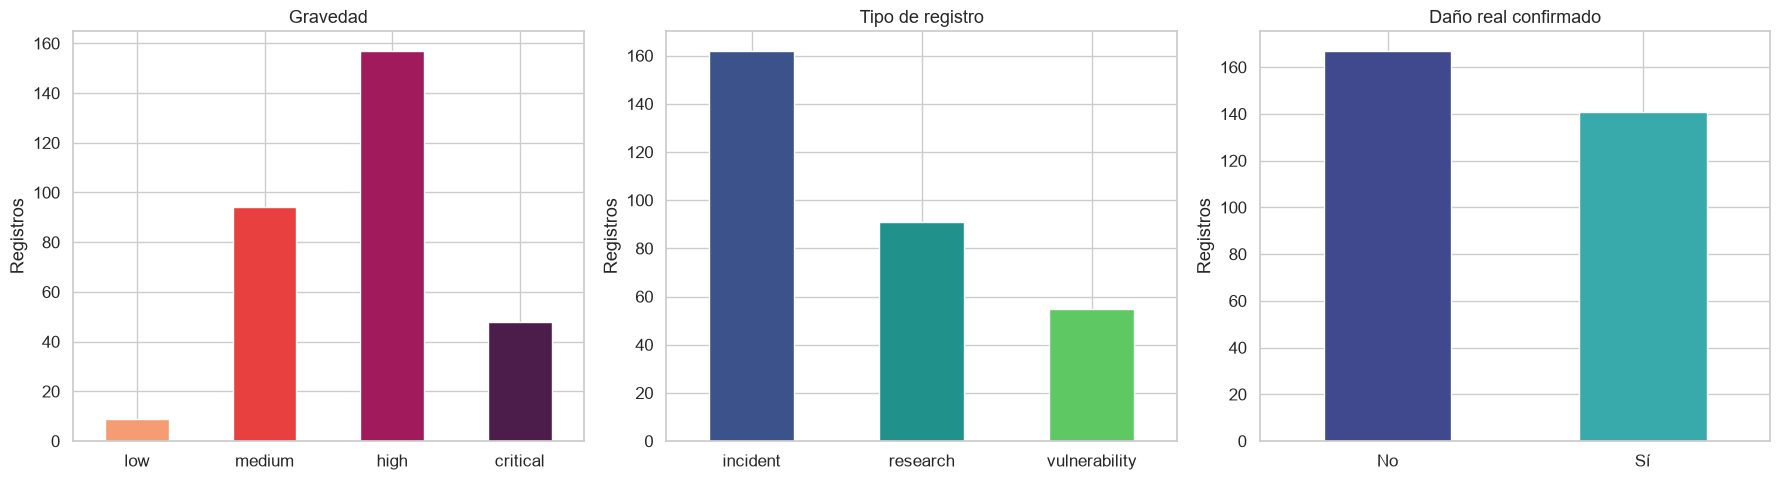

In [ ]:
#Creamos graficos que van a medir 3 variables, gravedad, tipo de registro y daño real confirmado
fig, ax = plt.subplots(1, 3, figsize=(18, 5)) #Tamaño de cada grafico y orden de los sub graficos

g = df["gravedad"].value_counts().reindex(orden_grav) #Cuenta cada columna de gravedad y los ordena
g.plot(kind="bar", ax=ax[0], color=sns.color_palette("rocket_r", len(g))) #Estilo de grafico
ax[0].set_title("Gravedad") #Definimos el titulo

t = df["tipo_registro"].value_counts() #Cuenta los registros de la variable tipo_registro 
t.plot(kind="bar", ax=ax[1], color=sns.color_palette("viridis", len(t)))#Estilo de grafico
ax[1].set_title("Tipo de registro")#Definimos el titulo

d = df["dano_real_confirmado"].map({0: "No", 1: "Sí"}).value_counts() #Mapeamos ordenando el 0 como no y el 1 como si y acomodandolos con base a su suma
d.plot(kind="bar", ax=ax[2], color=sns.color_palette("mako", len(d))) #Estilo de grafico
ax[2].set_title("Daño real confirmado") #Definimos titulo

for a in ax:
    a.set_xlabel("") #Borra el texto horizontal del eje
    a.set_ylabel("Registros") #Coloca el texto en la parte vertical
    a.tick_params(axis="x", rotation=0) #Deja horizontales los nombres de las categorías del eje X
plt.tight_layout() #Evita que los titulos y barras se interpongan entre si
plt.show() #Muestra el resultado